# original LR

In [1]:
# import libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# read data
df = pd.read_csv(r'D:\STUDY\internship\code_internship\dataset\sensor\data_prepared.csv')
df.head()

,material,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold,stage
0,steel-glass,100,10,10,1,0.023768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
1,steel-glass,100,10,10,2,0.024692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
2,steel-glass,100,10,10,3,0.024137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
3,steel-glass,100,10,10,4,0.024139,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
4,steel-glass,100,10,10,5,0.023798,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one


In [3]:
# features and labels
X = df.drop(columns=['material', 'stroke', 'stage', 'cycle'])
y = df['stage']

# use stratify to make sure the test data includes all labels.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)
print("数据集信息:")
print(f"特征数: {X.shape[1]}, 样本数: {X.shape[0]}, 类别数: {len(np.unique(y))}")

数据集信息:
特征数: 13, 样本数: 4838, 类别数: 5


In [4]:
# 特征标准化（重要：逻辑回归对特征尺度敏感）
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Create and train a logistic regression model
# Use multi_class='multinomial' to handle 5-class classification problems
# Solver='lbfgs' is suitable for small and medium-sized datasets
model = LogisticRegression(
    multi_class='multinomial',  # Multi-category settings
    solver='lbfgs',             # Optimization Algorithm
    max_iter=1000,              # Increase the number of iterations to ensure convergence
    random_state=42,
    class_weight='balanced'    # Deal with class imbalance
)

# Train the model
model.fit(X_train_scaled, y_train)

d:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(class_weight='balanced', max_iter=1000,
                   multi_class='multinomial', random_state=42)

Accuracy: 0.61

Classification report of original model:
              precision    recall  f1-score   support

        five       0.50      0.41      0.45       333
        four       0.64      0.57      0.60       441
         one       0.91      1.00      0.95       328
       three       0.25      0.44      0.32       126
         two       0.57      0.52      0.54       224

    accuracy                           0.61      1452
   macro avg       0.58      0.59      0.57      1452
weighted avg       0.63      0.61      0.61      1452


Feature importance of original model:
coe                        2.508704
osc_freq                   0.784882
ASL                        0.683847
Parametric 1               0.637618
Peak Frequency             0.573298
Parametric 2               0.495310
Threshold                  0.486263
force                      0.457787
Amplitude                  0.426984
Absolute Energy            0.209586
Initiation Frequency       0.189786
Reverberation Frequ

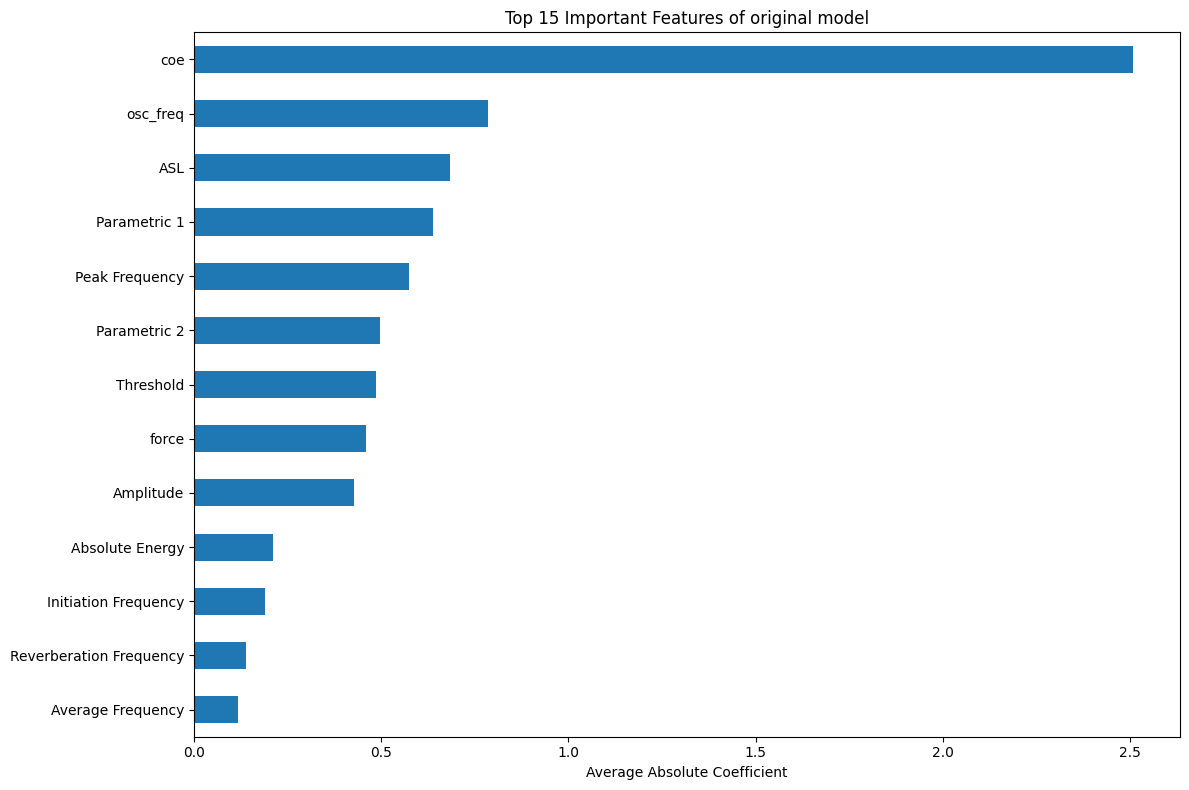

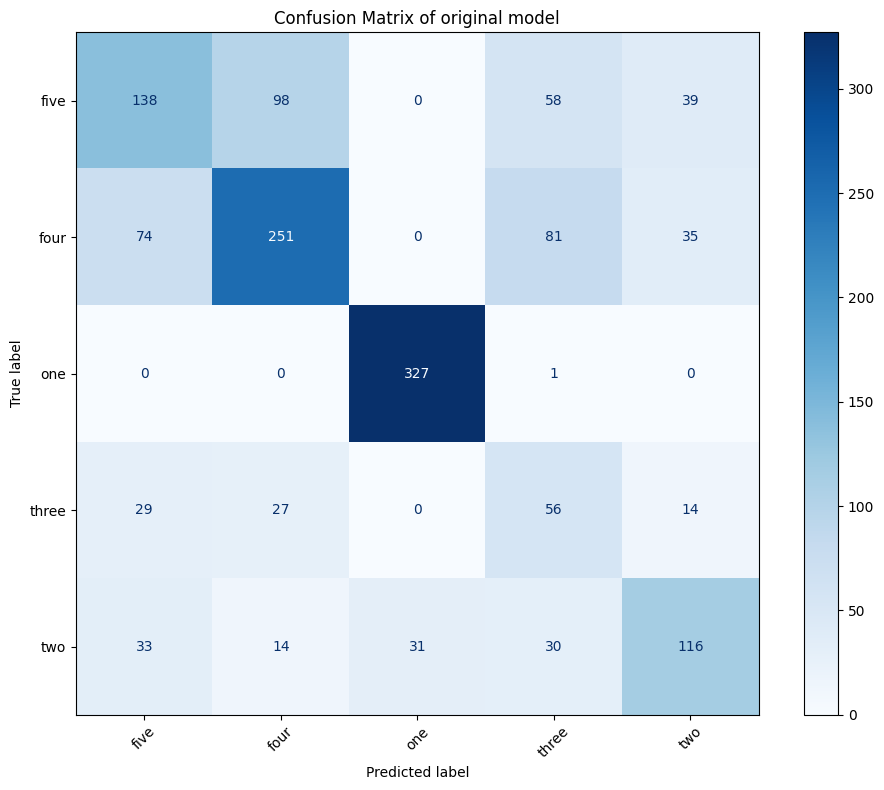

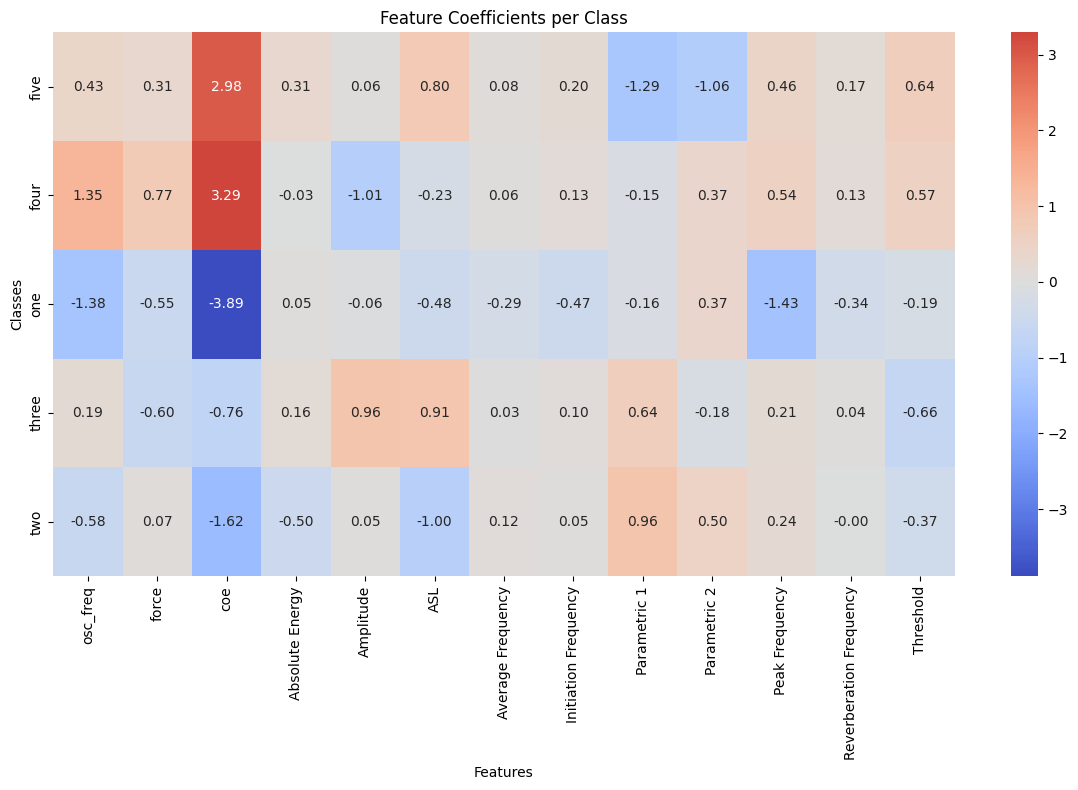

In [6]:
# 4. Model Evaluation
# Predict the test set
y_pred = model.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification report of original model:")
print(classification_report(y_test, y_pred, target_names=model.classes_.astype(str)))

# Feature importance analysis (using the average of the absolute values of the coefficients)
feature_importances = pd.Series(
    np.abs(model.coef_).mean(axis=0), # Take the average of the absolute values of all category coefficients
    index=X.columns
)
print("\nFeature importance of original model:")
print(feature_importances.sort_values(ascending=False))

# Visualizing important features
top_features = feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 8))
top_features.sort_values().plot(kind='barh')
plt.title('Top 15 Important Features of original model')
plt.xlabel('Average Absolute Coefficient')
plt.tight_layout()
plt.show()

# Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    display_labels=model.classes_,
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)
plt.title('Confusion Matrix of original model')
plt.tight_layout()
plt.show()

# coefficient heatmap (enhanced interpretability)
plt.figure(figsize=(12, 8))
sns.heatmap(
    pd.DataFrame(model.coef_, columns=X.columns, index=model.classes_),
    annot=True, 
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title('Feature Coefficients per Class')
plt.xlabel('Features')
plt.ylabel('Classes')
plt.tight_layout()
plt.show()

主要问题分析：

1.类别不平衡严重：

    "three"类（126样本）和"five"类（333样本）表现较差

    "one"类（328样本）表现极好（F1=0.95），表明模型偏向多数类

2.特征重要性分布不均：

    "coe"特征的重要性(2.52)远高于其他特征(大多<0.8)

    可能存在主导特征压制其他特征作用

3.特定类别表现差：

    "three"类的精确率仅0.27（大量误报）

    "five"类的召回率仅0.41（大量漏报）

# improved model with balanced dataset

Original training set category distribution
Counter({'four': 1030, 'five': 776, 'one': 765, 'two': 522, 'three': 293})

:Category distribution after SMOTE oversampling
Counter({'five': 1030, 'two': 1030, 'one': 1030, 'four': 1030, 'three': 1030})

Accuracy of balanced model: 0.6274

Classification report of balanced model:
              precision    recall  f1-score   support

        five       0.53      0.44      0.48       333
        four       0.66      0.60      0.63       441
         one       0.91      1.00      0.95       328
       three       0.26      0.44      0.33       126
         two       0.59      0.52      0.55       224

    accuracy                           0.63      1452
   macro avg       0.59      0.60      0.59      1452
weighted avg       0.64      0.63      0.63      1452


Important Features of balanced model:
coe                        2.656882
osc_freq                   0.792521
ASL                        0.781086
Parametric 1               0.711589
Pea

d:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


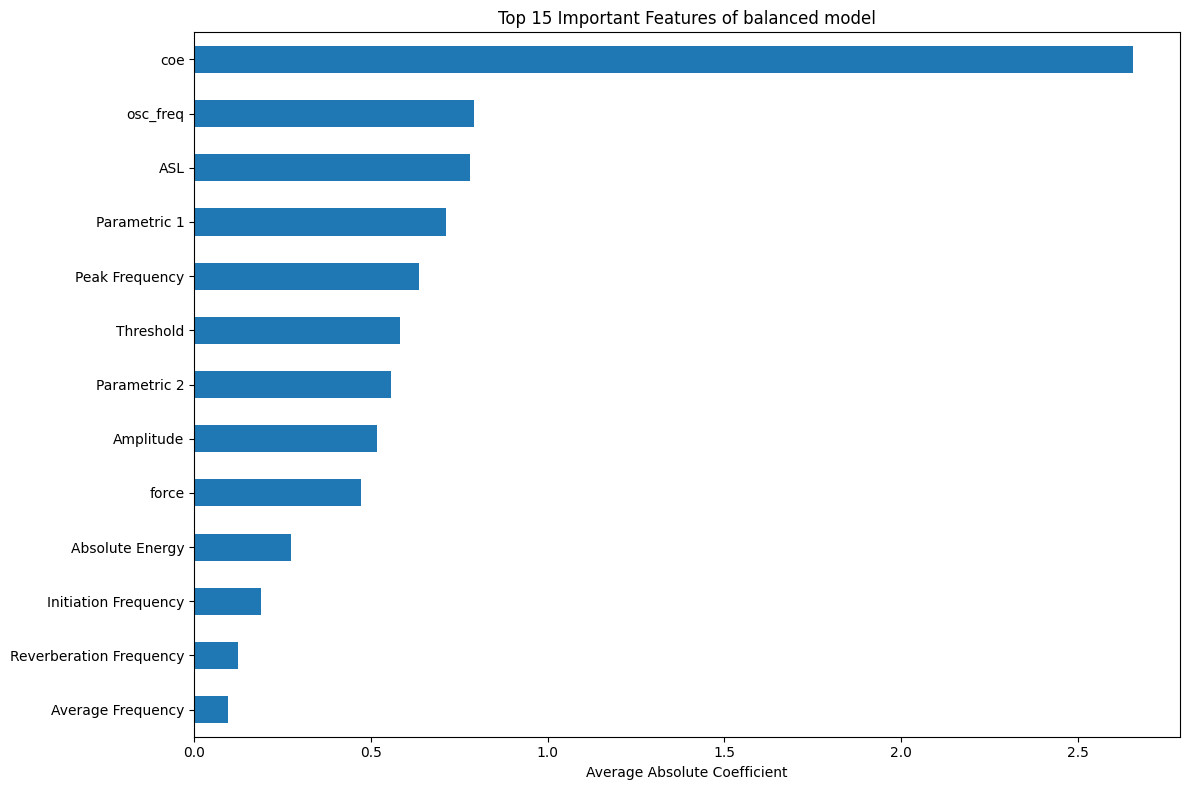

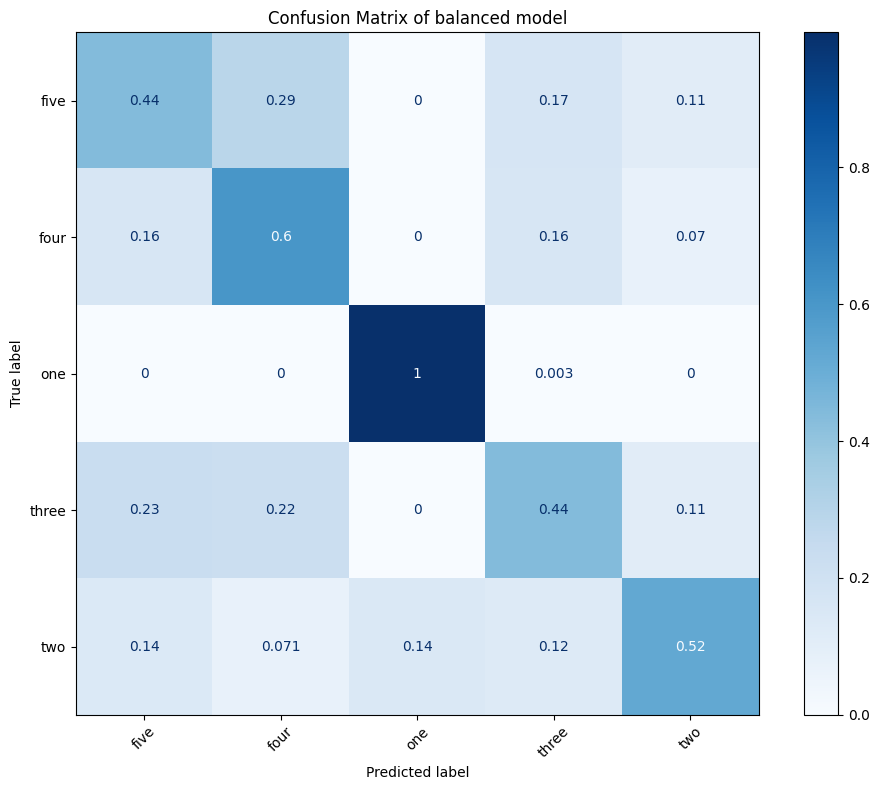

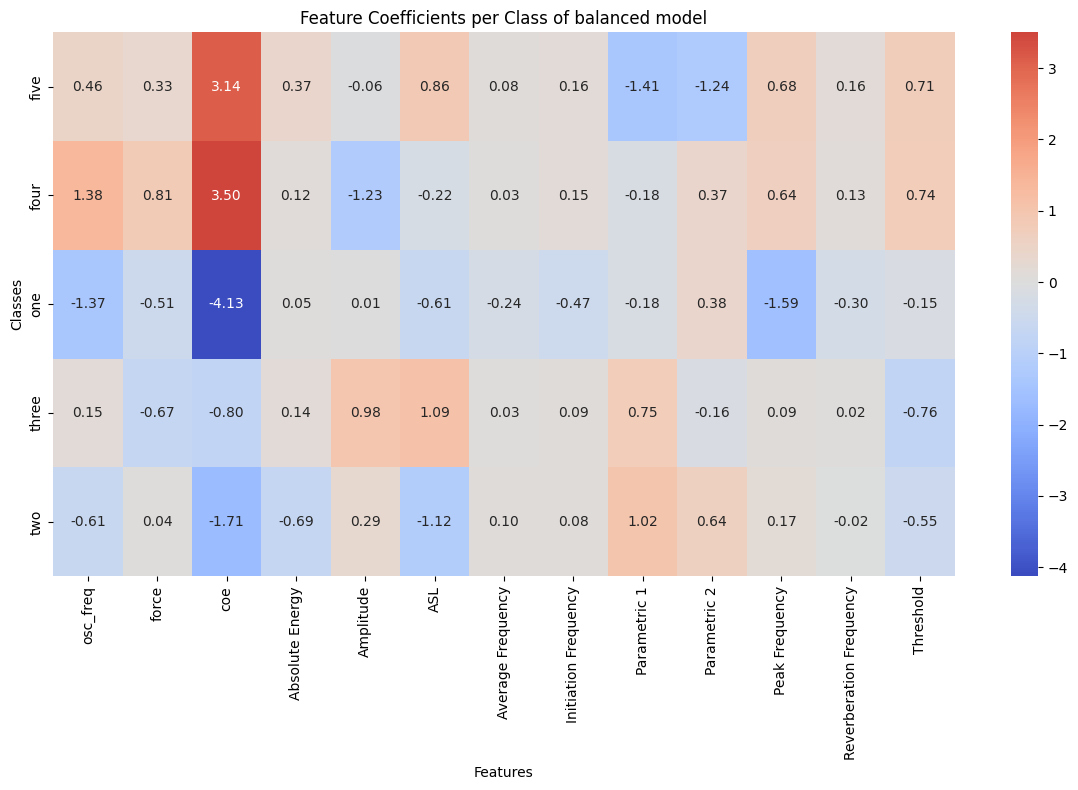

In [7]:
# 1. Dealing with class imbalance - Oversampling with SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import make_pipeline
from collections import Counter

# Display the original category distribution
print("Original training set category distribution")
print(Counter(y_train))

# Apply SMOTE oversampling
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

# Display the category distribution after oversampling
print("\n:Category distribution after SMOTE oversampling")
print(Counter(y_train_res))

# 2. Use the same logistic regression model, but train it on the balanced data
balanced_model = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    class_weight='balanced'  
)

# train the model
balanced_model.fit(X_train_res, y_train_res)

# 3. evaluate the model
# predict
y_pred_balanced = balanced_model.predict(X_test_scaled)

# accuracy
print(f"\nAccuracy of balanced model: {accuracy_score(y_test, y_pred_balanced):.4f}")
print("\nClassification report of balanced model:")
print(classification_report(y_test, y_pred_balanced, target_names=balanced_model.classes_.astype(str)))

# 4. the importance of features in the balanced model
balanced_feature_importances = pd.Series(
    np.abs(balanced_model.coef_).mean(axis=0),
    index=X.columns
)
print("\nImportant Features of balanced model:")
print(balanced_feature_importances.sort_values(ascending=False))

# Visualizing important features in the balanced model
top_balanced_features = balanced_feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 8))
top_balanced_features.sort_values().plot(kind='barh')
plt.title('Top 15 Important Features of balanced model')
plt.xlabel('Average Absolute Coefficient')
plt.tight_layout()
plt.show()

# 5. Confusion Matrix of the balanced model
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_balanced,
    display_labels=balanced_model.classes_,
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    normalize='true'  # Normalize the confusion matrix to show proportions
)
plt.title('Confusion Matrix of balanced model')
plt.tight_layout()
plt.show()

# 6. coefficient heatmap of the balanced model
plt.figure(figsize=(12, 8))
sns.heatmap(
    pd.DataFrame(balanced_model.coef_, columns=X.columns, index=balanced_model.classes_),
    annot=True, 
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title('Feature Coefficients per Class of balanced model')
plt.xlabel('Features')
plt.ylabel('Classes')
plt.tight_layout()
plt.show()

从结果来看，使用SMOTE过采样后模型性能没有明显提升，尤其是在关键类别"three"上。